## Updating Feature Layers

We will look at 2 patterns of updating existing feature layers:
1. Editing existing data of a `FeatureLayer`
2. Overwriting the `FeatureLayer` entirely.

#### Import necessary libraries and connect to GIS

In [56]:
from arcgis.gis import GIS
from arcgis.features import FeatureLayer, FeatureLayerCollection

gis = GIS("home")

You are logged on as MMajumdar_geosaurus with an administrator role, proceed with caution.


### Pattern 1: Editing existing data of a `FeatureLayer`

#### Define inputs

In [33]:
layer_url = "<SERVICE-URL-FOR-LAYER-TO-UPDATE>"

query_condition = "<QUERY-TO-FILTER-DATA-BY>" # set it to "1=1" to fetch all the data

#### Fetch the layer and query it

In [35]:
layer1 = FeatureLayer(layer_url)

In [37]:
fset1 = layer1.query(where=query_condition)
query_features = fset1.features

If you wish to edit a single feature you can access it using its index as shown below.

In [38]:
query_features[0].attributes

{'FID': 1178,
 'Year': '2023-24',
 'FedID': '060161410947',
 'CDSCode': '01100170112607',
 'CDCode': '0110017',
 'SCode': '0112607',
 'Region': '04',
 'CountyName': 'Alameda',
 'DistrictNa': 'Alameda County Office of Education',
 'SchoolName': 'Envision Academy for Arts & Technology',
 'SchoolType': 'K-12',
 'Status': 'Active',
 'OpenDate': 1156723200000,
 'ClosedDate': -2209161600000,
 'SchoolLeve': 'High',
 'GradeLow': '06',
 'GradeHigh': '12',
 'Charter': 'Y',
 'CharterNum': '0811',
 'FundingTyp': 'Directly funded',
 'Virtual': 'N',
 'Magnet': 'N',
 'TitleIStat': 'Y',
 'DASS': 'N',
 'AssistStat': 'ATSI',
 'Street': '1515 Webster St.',
 'City': 'Oakland',
 'Zip': '94612',
 'State': 'CA',
 'CongUS': '12',
 'SenateCA': '07',
 'AssemblyCA': '18',
 'Locale': '11 - City, Large',
 'Latitude': 37.80467596,
 'Longitude': -122.2683662,
 'EnrollTota': 223,
 'AAcount': 80,
 'AApct': 35.9,
 'AIcount': 1,
 'AIpct': 0.4,
 'AScount': 2,
 'ASpct': 0.9,
 'FIcount': 0,
 'FIpct': 0,
 'HIcount': 108,
 '

#### Editing the whole `FeatureSet`

To edit the whole `FeatureSet` object we have, you will have to specify the column name(s) and new value(s) to update with.

In [40]:
column_name = "<NAME-OF-COLUMN-WITH-DATA-TO-UPDATE>"
new_value = "<NEW-VALUES-TO-UPDATE>"

#### Apply the edits to the `FeatureLayer`

In [47]:
update_result = layer1.edit_features(updates=query_features)
update_result

{'addResults': [],
 'updateResults': [{'objectId': 1178,
   'uniqueId': 1178,
   'globalId': None,
   'success': True},
  {'objectId': 1202, 'uniqueId': 1202, 'globalId': None, 'success': True},
  {'objectId': 1203, 'uniqueId': 1203, 'globalId': None, 'success': True},
  {'objectId': 1204, 'uniqueId': 1204, 'globalId': None, 'success': True},
  {'objectId': 1205, 'uniqueId': 1205, 'globalId': None, 'success': True},
  {'objectId': 1206, 'uniqueId': 1206, 'globalId': None, 'success': True},
  {'objectId': 1207, 'uniqueId': 1207, 'globalId': None, 'success': True},
  {'objectId': 1208, 'uniqueId': 1208, 'globalId': None, 'success': True},
  {'objectId': 1209, 'uniqueId': 1209, 'globalId': None, 'success': True},
  {'objectId': 1210, 'uniqueId': 1210, 'globalId': None, 'success': True},
  {'objectId': 1211, 'uniqueId': 1211, 'globalId': None, 'success': True},
  {'objectId': 1212, 'uniqueId': 1212, 'globalId': None, 'success': True},
  {'objectId': 1213, 'uniqueId': 1213, 'globalId': None

#### Verify your updates 

In [52]:
layer1.query(where=column_name+"='"+new_value+"'", as_df=True).head()

,FID,Year,FedID,CDSCode,CDCode,SCode,Region,CountyName,DistrictNa,SchoolName,...,CountyCode,CountyNa_1,DistrictEl,District_1,DistrictHi,District_2,DistrictUn,District_3,ORIG_FID,SHAPE
0,1178,2023-24,060161410947,01100170112607,0110017,0112607,04,Alameda County,Alameda County Office of Education,Envision Academy for Arts & Technology,...,01,Alameda,,,,,0161259,Oakland Unified,30817,"{""x"": -13610852.265009362, ""y"": 4551869.703887..."
1,1202,2023-24,060169112844,01100170123968,0110017,0123968,04,Alameda County,Alameda County Office of Education,Community School for Creative Education,...,01,Alameda,,,,,0161259,Oakland Unified,30912,"{""x"": -13607560.992322305, ""y"": 4549083.796334..."
2,1203,2023-24,060201312901,01100170124172,0110017,0124172,04,Alameda County,Alameda County Office of Education,Yu Ming Charter,...,01,Alameda,,,,,0161259,Oakland Unified,39961,"{""x"": -13612383.221612522, ""y"": 4553754.734423..."
3,1204,2023-24,060181613008,01100170125567,0110017,0125567,04,Alameda County,Alameda County Office of Education,Urban Montessori Charter,...,01,Alameda,,,,,0161259,Oakland Unified,31050,"{""x"": -13601904.29134813, ""y"": 4549347.4794397..."
4,1205,2023-24,069105109264,01100170130401,0110017,0130401,04,Alameda County,Alameda County Office of Education,Alameda County Juvenile Hall/Court,...,01,Alameda,,,,,0161309,San Lorenzo Unified,39885,"{""x"": -13594139.977573834, ""y"": 4539377.261220..."


The same process can be followed to add or delete `Features` as demonstrated [here](https://developers.arcgis.com/python/latest/guide/editing-features/).

### Pattern 2: Overwriting the data of a `FeatureLayer`

If the data you wish to overwrite already exists in your workspace as a `.csv` file, please update the path to that file below (`csv_data_path`) and skip the cell that follows it. 

If the data you wish to overwrite exists on another service, please update the url for that service below (`service_url`) and run the cell that follows it to store its data as a `.csv` file in your workspace.

#### Define inputs

In [60]:
csv_data_path = "<PATH-TO-CSV-FILE-IN-WORKSPACE>"

# OR
service_url = "<SERVICE-URL-OF-TARGET-DATA>"

#### __Extract the data from the `service_url` as a `.csv` file in your workspace if you have provided a value to the `service_url` variable above__

In [54]:
layer2 = FeatureLayer(service_url)
df2 = layer2.query(as_df=True)
csv_data_path = '/arcgis/home/data_to_overwrite.csv'
df2.to_csv(csv_data_path)

#### Fetch the item to overwrite

<Item title:"gbr_cities_old" type:Feature Layer Collection owner:MMajumdar_geosaurus>
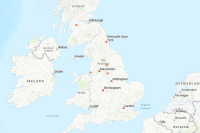

In [59]:
item_id = "<ITEMID-OF-ITEM-TO-OVERWRITE>"

item_to_overwrite = gis.content.get(item_id)
# Verify
item_to_overwrite

#### Perform the overwrite

In [ ]:
item_flayer_collection = FeatureLayerCollection(item_to_overwrite)
item_flayer_collection.manager.overwrite(data_file = csv_data_path)